# DATA 620 Project 1
## Comparing Degree Centrality and Eigenvector Centrality Among GitHub Developers

**Kevin DiPerna**

This project investigates whether Web Developers and Machine Learning Developers occupy different positions within the GitHub social network by comparing degree centrality and eigenvector centrality.

## Dataset

This project uses the GitHub Social Network dataset from the Stanford Network Analysis Project (SNAP). Nodes represent GitHub developers and edges represent mutual follower relationships. Each node includes a categorical variable (`ml_target`) identifying whether the developer is primarily a **Web Developer** or a **Machine Learning Developer**.

## Methodology

The analysis was completed using Python and the NetworkX library.

The following steps were performed:

1. Load the GitHub edge list and node attributes.
2. Construct an undirected network.
3. Calculate degree centrality for every node.
4. Calculate eigenvector centrality for every node.
5. Merge the centrality measures with the developer categories.
6. Compare the two developer groups using summary statistics and Welch's two-sample t-tests.
7. Visualize the results using boxplots and a sampled network graph.

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
import os

# --------------------------------------------------
# FILE PATHS
# --------------------------------------------------

folder = "/Users/kevindiperna/Desktop/git_web_ml"

edges_path = os.path.join(folder, "musae_git_edges.csv")
nodes_path = os.path.join(folder, "musae_git_target.csv")

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

edges = pd.read_csv(edges_path)
nodes = pd.read_csv(nodes_path)

# --------------------------------------------------
# BASIC DATASET INFORMATION
# --------------------------------------------------

print("EDGES DATASET")
print("----------------------------")
print("Shape:", edges.shape)
print("Columns:", list(edges.columns))
print(edges.head())

print("\nNODES DATASET")
print("----------------------------")
print("Shape:", nodes.shape)
print("Columns:", list(nodes.columns))
print(nodes.head())

# --------------------------------------------------
# CHECK FOR MISSING VALUES
# --------------------------------------------------

print("\nMISSING VALUES - EDGES")
print("----------------------------")
print(edges.isnull().sum())

print("\nMISSING VALUES - NODES")
print("----------------------------")
print(nodes.isnull().sum())

# --------------------------------------------------
# BUILD NETWORK
# --------------------------------------------------

G = nx.from_pandas_edgelist(
    edges,
    source="id_1",
    target="id_2",
    create_using=nx.Graph()
)

# --------------------------------------------------
# NETWORK SUMMARY
# --------------------------------------------------

print("\nNETWORK SUMMARY")
print("----------------------------")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is connected:", nx.is_connected(G))

# --------------------------------------------------
# CATEGORY SUMMARY
# --------------------------------------------------

print("\nCATEGORY COUNTS")
print("----------------------------")

if "ml_target" in nodes.columns:
    print(nodes["ml_target"].value_counts())
else:
    print("Available columns:", list(nodes.columns))

# --------------------------------------------------
# PREVIEW NODE IDS
# --------------------------------------------------

print("\nFIRST 10 NETWORK NODES")
print("----------------------------")
print(list(G.nodes())[:10])

EDGES DATASET
----------------------------
Shape: (289003, 2)
Columns: ['id_1', 'id_2']
   id_1   id_2
0     0  23977
1     1  34526
2     1   2370
3     1  14683
4     1  29982

NODES DATASET
----------------------------
Shape: (37700, 3)
Columns: ['id', 'name', 'ml_target']
   id          name  ml_target
0   0        Eiryyy          0
1   1    shawflying          0
2   2   JpMCarrilho          1
3   3     SuhwanCha          0
4   4  sunilangadi2          1

MISSING VALUES - EDGES
----------------------------
id_1    0
id_2    0
dtype: int64

MISSING VALUES - NODES
----------------------------
id           0
name         0
ml_target    0
dtype: int64

NETWORK SUMMARY
----------------------------
Number of nodes: 37700
Number of edges: 289003
Is connected: True

CATEGORY COUNTS
----------------------------
ml_target
0    27961
1     9739
Name: count, dtype: int64

FIRST 10 NETWORK NODES
----------------------------
[0, 23977, 1, 34526, 2370, 14683, 29982, 21142, 20363, 23830]


## Centrality Measures

Degree centrality was calculated for every developer to measure the proportion of direct connections each node has within the network. Eigenvector centrality was also calculated to measure a developer's influence based on both the number and importance of its connections. These measures were merged back into the node dataset for comparison across the two developer categories.


In [2]:
# --------------------------------------------------
# CALCULATE CENTRALITY MEASURES
# --------------------------------------------------

print("Calculating degree centrality...")
degree_centrality = nx.degree_centrality(G)

print("Calculating eigenvector centrality...")
eigenvector_centrality = nx.eigenvector_centrality(
    G,
    max_iter=1000,
    tol=1e-06
)

# --------------------------------------------------
# ADD CENTRALITY VALUES TO NODE DATAFRAME
# --------------------------------------------------

nodes["degree_centrality"] = nodes["id"].map(degree_centrality)
nodes["eigenvector_centrality"] = nodes["id"].map(eigenvector_centrality)

# --------------------------------------------------
# CHECK RESULTS
# --------------------------------------------------

print("\nCENTRALITY DATA PREVIEW")
print("----------------------------")
print(
    nodes[
        ["id", "ml_target", "degree_centrality", "eigenvector_centrality"]
    ].head()
)

print("\nMISSING CENTRALITY VALUES")
print("----------------------------")
print(
    nodes[
        ["degree_centrality", "eigenvector_centrality"]
    ].isnull().sum()
)

# --------------------------------------------------
# SUMMARY BY CATEGORY
# --------------------------------------------------

centrality_summary = nodes.groupby("ml_target")[
    ["degree_centrality", "eigenvector_centrality"]
].agg(["mean", "median", "std", "count"])

print("\nCENTRALITY SUMMARY BY GROUP")
print("----------------------------")
print(centrality_summary)

# --------------------------------------------------
# LABEL GROUPS FOR READABILITY
# --------------------------------------------------

nodes["developer_type"] = nodes["ml_target"].map({
    0: "Web Developer",
    1: "Machine Learning Developer"
})

print("\nDEVELOPER TYPE COUNTS")
print("----------------------------")
print(nodes["developer_type"].value_counts())

Calculating degree centrality...
Calculating eigenvector centrality...

CENTRALITY DATA PREVIEW
----------------------------
   id  ml_target  degree_centrality  eigenvector_centrality
0   0          0           0.000027                0.000047
1   1          0           0.000212                0.000952
2   2          1           0.000027                0.000036
3   3          0           0.000133                0.000105
4   4          1           0.000053                0.000009

MISSING CENTRALITY VALUES
----------------------------
degree_centrality         0
eigenvector_centrality    0
dtype: int64

CENTRALITY SUMMARY BY GROUP
----------------------------
          degree_centrality                            eigenvector_centrality  \
                       mean    median       std  count                   mean   
ml_target                                                                       
0                  0.000469  0.000159  0.002461  27961               0.002799   
1       

## Statistical Comparison

After calculating the centrality measures, Welch's two-sample t-tests were performed to compare Web Developers and Machine Learning Developers. Welch's test was selected because the two groups differ in size and may have unequal variances. Mean centrality values were also computed for each group.


In [4]:
# --------------------------------------------------
# T-TESTS
# --------------------------------------------------

from scipy.stats import ttest_ind

web = nodes[nodes["developer_type"] == "Web Developer"]
ml = nodes[nodes["developer_type"] == "Machine Learning Developer"]

# Degree Centrality
degree_ttest = ttest_ind(
    web["degree_centrality"],
    ml["degree_centrality"],
    equal_var=False
)

# Eigenvector Centrality
eigen_ttest = ttest_ind(
    web["eigenvector_centrality"],
    ml["eigenvector_centrality"],
    equal_var=False
)

print("DEGREE CENTRALITY T-TEST")
print("--------------------------------")
print(degree_ttest)

print("\nEIGENVECTOR CENTRALITY T-TEST")
print("--------------------------------")
print(eigen_ttest)

# --------------------------------------------------
# GROUP MEANS
# --------------------------------------------------

print("\nGROUP MEANS")
print("--------------------------------")

print(
    nodes.groupby("developer_type")[
        ["degree_centrality","eigenvector_centrality"]
    ].mean()
)

DEGREE CENTRALITY T-TEST
--------------------------------
TtestResult(statistic=np.float64(15.084386275493475), pvalue=np.float64(2.968356554862816e-51), df=np.float64(35202.627063752094))

EIGENVECTOR CENTRALITY T-TEST
--------------------------------
TtestResult(statistic=np.float64(46.152805784184366), pvalue=np.float64(0.0), df=np.float64(37690.36247776537))

GROUP MEANS
--------------------------------
                            degree_centrality  eigenvector_centrality
developer_type                                                       
Machine Learning Developer           0.000229                0.001148
Web Developer                        0.000469                0.002799


## Results

The analysis found that **Web Developers had higher average degree centrality and higher average eigenvector centrality than Machine Learning Developers.**

Welch's t-tests showed that both differences were statistically significant (p < 0.001), indicating that the observed differences are unlikely to be due to random chance. The boxplots and network visualization support these findings by showing that Web Developers are more likely to occupy highly connected and influential positions within the network.

### Visualizations

The following boxplots compare the distributions of degree centrality and eigenvector centrality across the two developer groups. A connected sample of approximately 150 nodes is also visualized to illustrate the overall structure of the GitHub network. The visualization is intended for illustration only; all centrality calculations and statistical tests were performed using the complete network.


<Figure size 800x600 with 0 Axes>

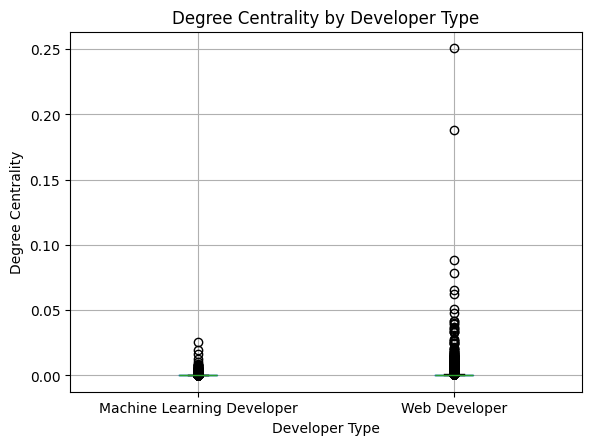

<Figure size 800x600 with 0 Axes>

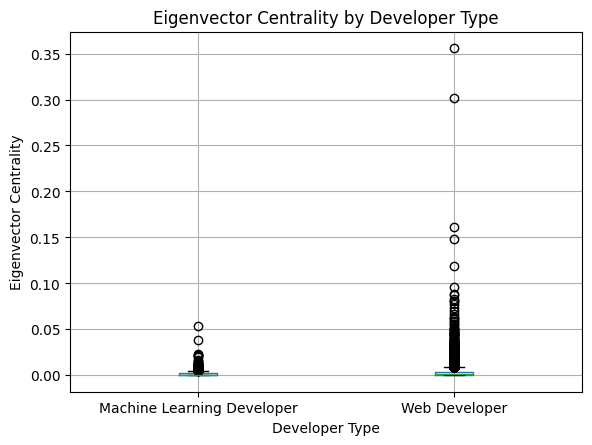

In [5]:
# --------------------------------------------------
# VISUALIZATIONS
# --------------------------------------------------

import matplotlib.pyplot as plt

plt.style.use("default")

# Degree Centrality
plt.figure(figsize=(8,6))
nodes.boxplot(column="degree_centrality", by="developer_type")
plt.title("Degree Centrality by Developer Type")
plt.suptitle("")
plt.xlabel("Developer Type")
plt.ylabel("Degree Centrality")
plt.show()

# Eigenvector Centrality
plt.figure(figsize=(8,6))
nodes.boxplot(column="eigenvector_centrality", by="developer_type")
plt.title("Eigenvector Centrality by Developer Type")
plt.suptitle("")
plt.xlabel("Developer Type")
plt.ylabel("Eigenvector Centrality")
plt.show()

Nodes: 150
Edges: 631


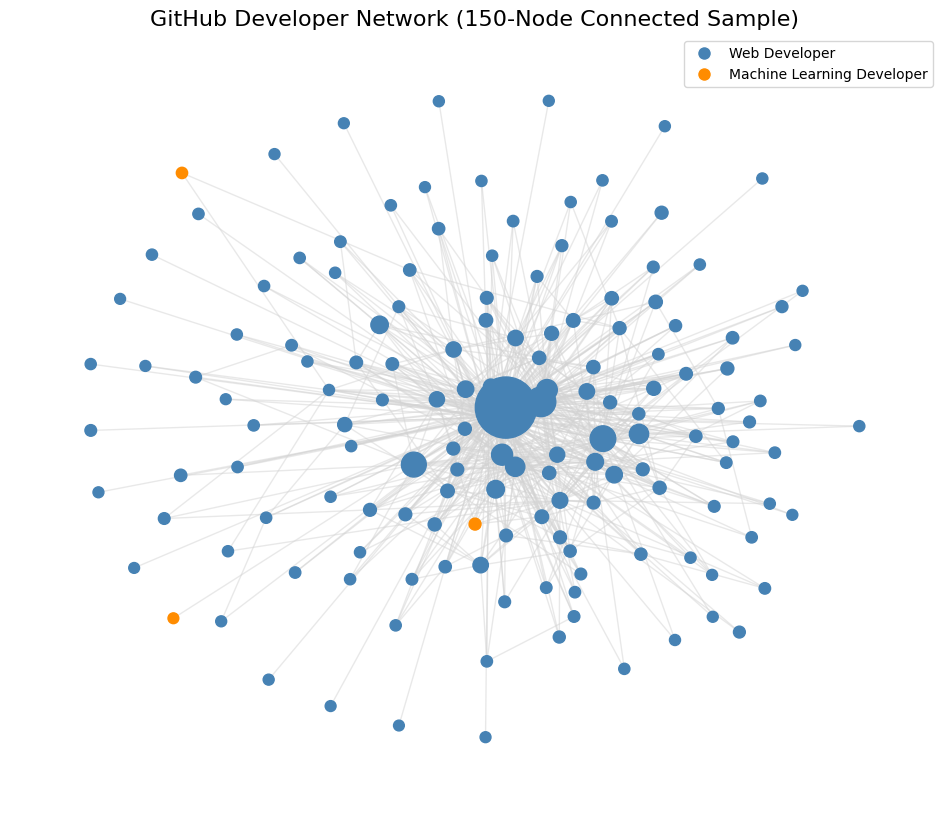

In [9]:
# --------------------------------------------------
# CONNECTED GITHUB NETWORK VISUALIZATION
# --------------------------------------------------

import random
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D

random.seed(42)

# Choose a random starting node
start_node = random.choice(list(G.nodes()))

# Breadth-first search to collect ~150 connected nodes
visited = set([start_node])
queue = deque([start_node])

while queue and len(visited) < 150:
    current = queue.popleft()

    neighbors = list(G.neighbors(current))
    random.shuffle(neighbors)

    for neighbor in neighbors:
        if neighbor not in visited:
            visited.add(neighbor)
            queue.append(neighbor)

        if len(visited) >= 150:
            break

# Create connected subgraph
subG = G.subgraph(visited).copy()

print("Nodes:", subG.number_of_nodes())
print("Edges:", subG.number_of_edges())

# Layout
pos = nx.spring_layout(subG, seed=42, k=0.25)

# Colors
colors = []

for node in subG.nodes():
    if nodes.loc[nodes["id"] == node, "ml_target"].values[0] == 0:
        colors.append("steelblue")
    else:
        colors.append("darkorange")

# Size nodes by degree centrality
sizes = [degree_centrality[node] * 10000 + 60 for node in subG.nodes()]

# Plot
plt.figure(figsize=(12,10))

nx.draw_networkx_edges(
    subG,
    pos,
    edge_color="lightgray",
    alpha=0.5
)

nx.draw_networkx_nodes(
    subG,
    pos,
    node_color=colors,
    node_size=sizes
)

plt.title("GitHub Developer Network (150-Node Connected Sample)", fontsize=16)

legend = [
    Line2D([0],[0], marker='o', color='w',
           markerfacecolor='steelblue',
           markersize=10,
           label='Web Developer'),
    Line2D([0],[0], marker='o', color='w',
           markerfacecolor='darkorange',
           markersize=10,
           label='Machine Learning Developer')
]

plt.legend(handles=legend)

plt.axis("off")
plt.show()

## Discussion and Conclusion

This project successfully met the objectives of identifying a network dataset with categorical node information, calculating degree centrality and eigenvector centrality for every node, and comparing these measures across developer groups.

Overall, Web Developers exhibited higher centrality values than Machine Learning Developers, suggesting they occupy more central positions within this GitHub social network. Future work could explore additional network measures such as betweenness centrality or investigate how network position relates to collaboration and productivity.

## References

- Stanford Network Analysis Project (SNAP): GitHub Social Network Dataset.
- NetworkX Documentation: https://networkx.org/